---
title: "conjugation"
execute:
  freeze: auto  # re-render only when source changes
format:
  html:
    code-fold: true
    code-summary: "Show the code"
---

I'd like to thank Adam Frank for his blog post on [axiomtutor.com](https://www.axiomtutor.com/new-blog?offset=1725466035734) for helping me grasp intuitively the concept of conjugation.

Conjugation represents the idea that one operation can be seen from two different points of view. I'll start with a concrete example.

Say that $k$ represents a reflection across the $x$-axis, and $g$ represents a counter-clockwise rotation by an arbitrary angle $\theta$. See below these two operations applied on a heart shape.

In [10]:
#| code-summary: import libraries
import numpy as np
from matplotlib.patches import Arc, RegularPolygon
import matplotlib.pyplot as plt
from numpy import radians as rad

In [11]:
#| code-summary: define useful functions
def drawCirc(ax,radius,centX,centY,angle_,theta2_,color_='black',linewidth=3):
    #========Line
    arc = Arc([centX,centY],radius,radius,angle=angle_,
          theta1=0,theta2=theta2_,capstyle='round',linestyle='-',lw=linewidth,color=color_)
    ax.add_patch(arc)


    #========Create the arrow head
    endX=centX+(radius/2)*np.cos(rad(theta2_+angle_)) #Do trig to determine end position
    endY=centY+(radius/2)*np.sin(rad(theta2_+angle_))
    
    ax.add_patch(
        RegularPolygon(
            (endX, endY),
            numVertices=3,
            radius=radius/5,
            orientation=rad(angle_ + theta2_),
            color=color_
        )
    )

In [12]:
#| code-summary: define transformations
red = 'xkcd:vermillion'
blue = 'xkcd:bright blue'
t = np.linspace(0, 2*np.pi, 100)
x = 16* (np.sin(t)) ** 3
y = 13* np.cos(t) - 5 * np.cos(2*t) - 2 * np.cos(3*t) - np.cos(4*t)
heart = np.array([x, y])
flip_x = np.array([[1, 0], [0, -1]])
def rotate(theta):
    return np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]])
heart_x = flip_x @ heart
theta = np.atan(0.5)
heart_minus_theta = rotate(-theta) @ heart
heart_minus_theta_flipped = flip_x @ heart_minus_theta
heart_minus_theta_flipped_plus_theta = rotate(theta) @ heart_minus_theta_flipped
x_oblique_axis = np.array([-25, 25])
y_oblique_axis = 0.5 * x_oblique_axis
oblique_axis = np.array([x_oblique_axis, y_oblique_axis])
oblique_axis_minus_theta = rotate(-theta) @ oblique_axis
oblique_axis_minus_theta_plus_theta = rotate(theta) @ oblique_axis_minus_theta

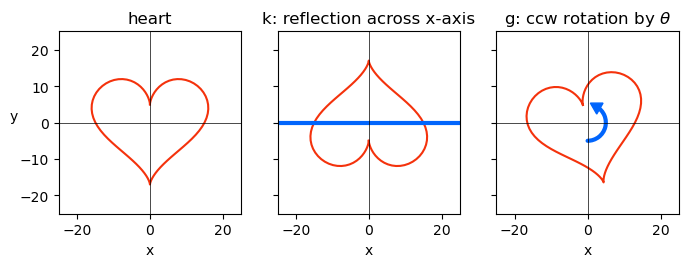

In [13]:
#| code-summary: plot k and g applied to a heart shape
fig, ax = plt.subplots(1, 3, sharey=True, figsize=(8, 4))
ax[0].plot(heart[0], heart[1], color=red)
ax[0].axhline(0, color='black', lw=0.5)
ax[0].axvline(0, color='black', lw=0.5)
ax[0].set_aspect('equal')
ax[0].set(xlabel='x', title='heart', xlim=x_oblique_axis, ylim=x_oblique_axis)
ax[0].set_ylabel('y', rotation=0)

ax[1].plot(heart_x[0], heart_x[1], color=red)
ax[1].axhline(0, color=blue, lw=3)
ax[1].axvline(0, color='black', lw=0.5)
ax[1].set_aspect('equal')
ax[1].set(xlabel='x', title='k: reflection across x-axis', xlim=x_oblique_axis, ylim=x_oblique_axis)

heart_15 = rotate(np.pi/12) @ heart
ax[2].plot(heart_15[0], heart_15[1], color=red)
ax[2].axhline(0, color='black', lw=0.5)
ax[2].axvline(0, color='black', lw=0.5)
ax[2].set_aspect('equal')
ax[2].set(xlabel='x', title=r'g: ccw rotation by $\theta$', xlim=x_oblique_axis, ylim=x_oblique_axis)
drawCirc(ax[2],radius=10,centX=0,centY=0,angle_=270,theta2_=150, color_=blue);

Because we are dealing with operations on a 2d plane, both $k$ and $g$ can be represented as $2\times2$ matrices:

$$
k =
\begin{pmatrix}
1 & 0 \\
0 & -1
\end{pmatrix}
\quad\text{and}\quad
g =
\begin{pmatrix}
\cos(\theta) & -\sin(\theta) \\
\sin(\theta) & \cos(\theta)
\end{pmatrix}
$$

What if we want to make a reflection of the heart shape across a different axis? In the graph below, the first panel on the left shows a reflection axis that is rotated by an angle $\theta$ from the $x$-axis. With a little ingenuity, I don't need to define a new reflection operation. Instead, I can use the existing reflection operation $k$ and the rotation operation $g$ to achieve the same effect.

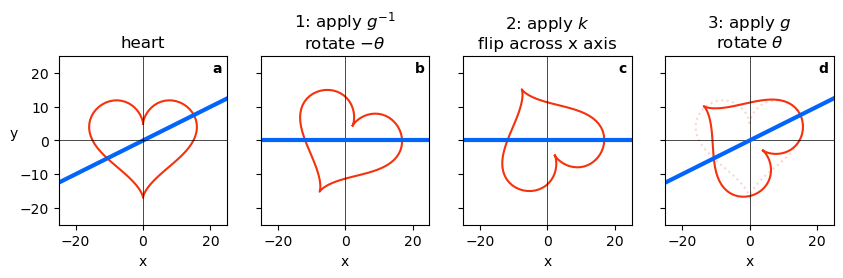

In [14]:
#| code-summary: conjugation of k and g applied to a heart shape
fig, ax = plt.subplots(1, 4, sharey=True, figsize=(10, 3))
ax[0].plot(heart[0], heart[1], color=red)
ax[0].plot(oblique_axis[0], oblique_axis[1], color=blue, lw=3)
ax[0].axhline(0, color='black', lw=0.5)
ax[0].axvline(0, color='black', lw=0.5)
ax[0].set_aspect('equal')
ax[0].set(xlabel='x', title='heart', xlim=x_oblique_axis, ylim=x_oblique_axis)
ax[0].set_ylabel('y', rotation=0)
ax[0].text(0.97, 0.97, r"a", transform=ax[0].transAxes,
         horizontalalignment='right', verticalalignment='top',
         fontweight="bold")

ax[1].plot(heart_minus_theta[0], heart_minus_theta[1], color=red)
ax[1].axhline(0, color='black', lw=0.5)
ax[1].axvline(0, color='black', lw=0.5)
ax[1].plot(oblique_axis_minus_theta[0], oblique_axis_minus_theta[1], color=blue, lw=3)
ax[1].set_aspect('equal')
ax[1].set(xlabel='x', title=r'1: apply $g^{-1}$' + "\n" + r'rotate $-\theta$', xlim=x_oblique_axis, ylim=x_oblique_axis)
ax[1].text(0.97, 0.97, r"b", transform=ax[1].transAxes,
         horizontalalignment='right', verticalalignment='top',
         fontweight="bold")

ax[2].plot(heart_minus_theta_flipped[0], heart_minus_theta_flipped[1], color=red)
ax[2].axhline(0, color='black', lw=0.5)
ax[2].axvline(0, color='black', lw=0.5)
ax[2].plot(oblique_axis_minus_theta[0], oblique_axis_minus_theta[1], color=blue, lw=3)
ax[2].set(xlabel='x', title=r'2: apply $k$' + "\n" + r'flip across x axis', xlim=x_oblique_axis, ylim=x_oblique_axis)
ax[2].text(0.97, 0.97, r"c", transform=ax[2].transAxes,
         horizontalalignment='right', verticalalignment='top',
         fontweight="bold")
ax[2].set_aspect('equal')

ax[3].plot(heart_minus_theta_flipped_plus_theta[0], heart_minus_theta_flipped_plus_theta[1], color=red)
ax[3].plot(heart[0], heart[1], color=red, alpha=0.2, ls=":")
ax[3].axhline(0, color='black', lw=0.5)
ax[3].axvline(0, color='black', lw=0.5)
ax[3].plot(oblique_axis_minus_theta_plus_theta[0], oblique_axis_minus_theta_plus_theta[1], color=blue, lw=3)
ax[3].set(xlabel='x', title=r'3: apply $g$' + "\n" + r'rotate $\theta$', xlim=x_oblique_axis, ylim=x_oblique_axis)
ax[3].text(0.97, 0.97, r"d", transform=ax[3].transAxes,
         horizontalalignment='right', verticalalignment='top',
         fontweight="bold")
ax[3].set_aspect('equal');

1. We rotate the whole plane by an angle $-\theta$, which rotates the reflection axis (blue) to coincide with the $x$-axis (2nd panel). This is equivalent to applying the inverse of the rotation operation $g^{-1}$ to the heart shape.
2. Then we reflect the (rotated) heart shape across the $x$-axis (3rd panel). This is simply applying the reflection operation $k$ to the rotated heart shape.
3. Finally, we rotate the whole plane back by an angle $\theta$ (4th panel). This is equivalent to applying the rotation operation $g$ to the reflected heart shape. You can check the result by comparing the solid red curve with the original heart shape shown with a dotted line.

Try it yourself: each slider below applies one of the three steps, in order. The rightmost panel shows the final result (solid) against the original heart (dotted) for comparison.

```{ojs}
{
  const π=Math.PI;
  const RED='#e45810';
  const RED_FILL='rgba(228,88,16,0.18)';
  const ORIGINAL='rgba(0,0,0,0.35)';
  const BLUE='#0485d1';
  const AXIS='#333333';
  const BG='#eeeeee';
  const lim=25;

  const thetaDeg=Math.atan(0.5)*180/π;   // ≈ 26.565°, same θ as the static figures above

  // same heart superformula used in the matplotlib cells above
  const N=200;
  const heart=d3.range(N).map(i=>{
    const t=2*π*i/(N-1);
    const x=16*Math.pow(Math.sin(t),3);
    const y=13*Math.cos(t)-5*Math.cos(2*t)-2*Math.cos(3*t)-Math.cos(4*t);
    return [x,y];
  });

  const obliqueAxis=[[-lim,-lim/2],[lim,lim/2]];  // slope 0.5, i.e. angle θ from the x-axis

  function rotate(deg) {
    const a=deg*π/180, c=Math.cos(a), s=Math.sin(a);
    return p=>[c*p[0]-s*p[1], s*p[0]+c*p[1]];
  }

  function flipProgress(t) {
    // continuously morphs the identity (t=0) into a full reflection y→-y (t=1)
    return p=>[p[0], p[1]*(1-2*t)];
  }

  function mapPts(points,fn) { return points.map(fn); }

  // ── one slider per step, each ranging over exactly that step's own journey:
  // 0 = the panel on its left (not yet applied), max = the panel on its right
  // (fully applied). Readout always shows plain progress, so "drag to 100%"
  // means the same thing for every slider regardless of what it controls.
  function makeSlider(label,max,step,fmt) {
    const wrap=document.createElement('div');
    wrap.style.cssText='margin-bottom:6px';

    const lbl=document.createElement('label');
    lbl.style.cssText='color:black;font-family:Arial,sans-serif;font-size:13px;'+
      'display:flex;justify-content:space-between;margin-bottom:1px';

    const name=document.createElement('span');
    name.textContent=label;
    name.style.fontWeight='bold';

    const readout=document.createElement('span');
    readout.textContent=fmt(0,max);

    lbl.append(name,readout);

    const inp=document.createElement('input');
    inp.type='range';
    inp.min=0; inp.max=max; inp.step=step; inp.value=0;
    inp.style.cssText='width:100%;display:block;cursor:pointer;margin:0';

    wrap.append(lbl,inp);
    return {wrap,inp,max,fmt};
  }

  const pct=(v,max)=>`${Math.round(100*v/max)}%`;

  const s1=makeSlider('slider 1 — a → b (apply g⁻¹)',thetaDeg,0.1,pct);
  const s2=makeSlider('slider 2 — b → c (apply k)',1,0.01,pct);
  const s3=makeSlider('slider 3 — c → d (apply g)',thetaDeg,0.1,pct);

  const sliderBox=document.createElement('div');
  sliderBox.style.cssText=`background:${BG};padding:10px;margin-bottom:10px;box-sizing:border-box;`;
  sliderBox.append(s1.wrap,s2.wrap,s3.wrap);

  // ── four panels, labeled a-d, matching the static figure above ──────────
  const panelW=170, panelH=170;
  const scale=(panelW-10)/(2*lim);
  const cx=panelW/2, cy=panelH/2;
  function X(x){ return cx+x*scale; }
  function Y(y){ return cy-y*scale; }

  function pathFor(points){
    return points.map((p,i)=>`${i===0?'M':'L'}${X(p[0]).toFixed(2)},${Y(p[1]).toFixed(2)}`).join(' ');
  }

  function makePanel(title,subtitle) {
    const wrap=document.createElement('div');
    wrap.style.cssText=`width:${panelW}px;background:${BG};padding:6px;box-sizing:border-box;`;

    const titleEl=document.createElement('div');
    titleEl.innerHTML=`<b>${title}</b> — ${subtitle}`;
    titleEl.style.cssText=
      'font-family:Arial,sans-serif;font-size:12px;margin-bottom:3px;'+
      'color:black;text-align:center';

    const svg=d3.create('svg')
      .attr('width',panelW)
      .attr('height',panelH)
      .style('background','white')
      .node();

    wrap.append(titleEl,svg);
    return {wrap,svg:d3.select(svg)};
  }

  const pA=makePanel('a','heart');
  const pB=makePanel('b','apply g⁻¹');
  const pC=makePanel('c','apply k');
  const pD=makePanel('d','apply g');

  function drawBaseAxes(svgSel) {
    svgSel.append('line').attr('x1',X(-lim)).attr('y1',Y(0)).attr('x2',X(lim)).attr('y2',Y(0))
      .attr('stroke',AXIS).attr('stroke-width',1);
    svgSel.append('line').attr('x1',X(0)).attr('y1',Y(-lim)).attr('x2',X(0)).attr('y2',Y(lim))
      .attr('stroke',AXIS).attr('stroke-width',1);
  }

  function drawHeart(svgSel,points,{fill=true,stroke=RED,dash=null,opacity=1}={}) {
    svgSel.append('path')
      .attr('d',pathFor(points)+' Z')
      .attr('fill',fill?RED_FILL:'none')
      .attr('stroke',stroke)
      .attr('stroke-width',1.8)
      .attr('stroke-dasharray',dash)
      .attr('opacity',opacity);
  }

  function drawAxisLine(svgSel,points) {
    svgSel.append('line')
      .attr('x1',X(points[0][0])).attr('y1',Y(points[0][1]))
      .attr('x2',X(points[1][0])).attr('y2',Y(points[1][1]))
      .attr('stroke',BLUE).attr('stroke-width',2);
  }

  function redraw() {
    const g1=+s1.inp.value, k2=+s2.inp.value, g3=+s3.inp.value;
    s1.wrap.querySelector('span:last-child').textContent=s1.fmt(g1,s1.max);
    s2.wrap.querySelector('span:last-child').textContent=s2.fmt(k2,s2.max);
    s3.wrap.querySelector('span:last-child').textContent=s3.fmt(g3,s3.max);

    const panelB=mapPts(heart,rotate(-g1));
    const axisB=mapPts(obliqueAxis,rotate(-g1));

    const panelC=mapPts(panelB,flipProgress(k2));
    const axisC=mapPts(axisB,flipProgress(k2));

    const panelD=mapPts(panelC,rotate(g3));
    const axisD=mapPts(axisC,rotate(g3));

    for (const p of [pA,pB,pC,pD]) p.svg.selectAll('*').remove();

    drawBaseAxes(pA.svg);
    drawAxisLine(pA.svg,obliqueAxis);
    drawHeart(pA.svg,heart);

    drawBaseAxes(pB.svg);
    drawAxisLine(pB.svg,axisB);
    drawHeart(pB.svg,panelB);

    drawBaseAxes(pC.svg);
    drawAxisLine(pC.svg,axisC);
    drawHeart(pC.svg,panelC);

    drawBaseAxes(pD.svg);
    drawAxisLine(pD.svg,axisD);
    drawHeart(pD.svg,heart,{fill:false,stroke:ORIGINAL,dash:'4 3'});
    drawHeart(pD.svg,panelD);
  }

  for (const s of [s1,s2,s3]) s.inp.addEventListener('input',redraw);
  redraw();

  const row=document.createElement('div');
  row.style.cssText='display:flex;gap:10px;flex-wrap:wrap';
  row.append(pA.wrap,pB.wrap,pC.wrap,pD.wrap);

  const container=document.createElement('div');
  container.append(sliderBox,row);
  return container;
}
```

To sum up: apply $g^{-1}$, then $k$, then $g$. Let's call the resulting operation $k'$, which is said to be a conjugate of $k$ by $g$:

$$
k' = g k g^{-1}.
$$

Now let's see the same thing from a slightly different perspective. If $k$ means reflecting across the $x$-axis, then $k'$ can also be interpreted as reflecting across the $x$-axis, but in a rotated coordinate system. See below, the usual axes $x$ and $y$ are used in the panel on the left, while a rotated coordinate system by $\theta$ is used in the panel on the right.

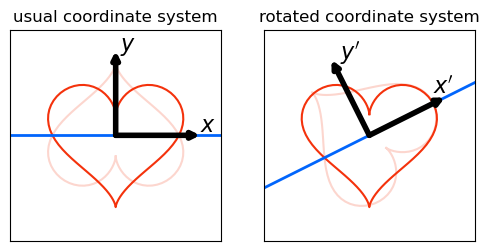

In [15]:
#| code-summary: conjugation of k and g applied to a heart shape
fig, ax = plt.subplots(1, 2, sharey=True, figsize=(6, 3))

ax[0].plot(heart[0], heart[1], color=red)
ax[0].plot(heart_x[0], heart_x[1], color=red, alpha=0.2)
ax[0].axhline(0, color=blue, lw=2)
ax[0].set_aspect('equal')
ax[0].set(title='usual coordinate system', xlim=x_oblique_axis, ylim=x_oblique_axis, xticks=[], yticks=[])
ax[0].annotate("", xy=(20, 0), xytext=(0, 0), fontsize=10, color="black", arrowprops=dict(arrowstyle="->", facecolor='black', lw=4, shrinkA=0, shrinkB=0),)
ax[0].annotate("", xy=(0, 20), xytext=(0, 0), fontsize=10, color="black", arrowprops=dict(arrowstyle="->", facecolor='black', lw=4, shrinkA=0, shrinkB=0),)
ax[0].text(20, 1, r'$x$', fontsize=16, color="black")
ax[0].text(1, 20, r'$y$', fontsize=16, color="black")

ex = np.array([[20,0]])
x_prime = rotate(theta) @ ex.T
why = np.array([[0,20]])
y_prime = rotate(theta) @ why.T

ax[1].plot(heart[0], heart[1], color=red)
ax[1].plot(heart_minus_theta_flipped_plus_theta[0], heart_minus_theta_flipped_plus_theta[1], color=red, alpha=0.2)
ax[1].plot(oblique_axis[0], oblique_axis[1], color=blue, lw=2)
ax[1].set_aspect('equal')
ax[1].set(title='rotated coordinate system', xlim=x_oblique_axis, ylim=x_oblique_axis, xticks=[], yticks=[])
ax[1].annotate("", xy=x_prime, xytext=(0, 0), fontsize=10, color="black", arrowprops=dict(arrowstyle="->", facecolor='black', lw=4, shrinkA=0, shrinkB=0),)
ax[1].annotate("", xy=y_prime, xytext=(0, 0), fontsize=10, color="black", arrowprops=dict(arrowstyle="->", facecolor='black', lw=4, shrinkA=0, shrinkB=0),)
ax[1].text(15, 10, r"$x'$", fontsize=16, color="black")
ax[1].text(-7, 18, r"$y'$", fontsize=16, color="black");

The rotated coordinate system is defined by unit vectors $x'$ and $y'$ which are exactly the column vectors of the rotation matrix $g$!

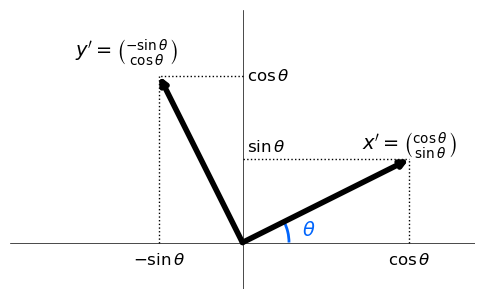

In [18]:
#| code-summary: coordinates of the rotated axes
fig, ax = plt.subplots(1, 1, figsize=(6, 4))
ax.set_aspect('equal')
ax.set(xlim=x_oblique_axis,
       ylim=[0.2*x_oblique_axis[0], x_oblique_axis[1]],
       xticks=[],
       yticks=[])
ax.set_frame_on(False)
ax.axhline(0, color="black", lw=0.5)
ax.axvline(0, color="black", lw=0.5)

ax.annotate("", xy=x_prime, xytext=(0, 0), fontsize=10, color="black", arrowprops=dict(arrowstyle="->", facecolor='black', lw=4, shrinkA=0, shrinkB=0),)
ax.annotate("", xy=y_prime, xytext=(0, 0), fontsize=10, color="black", arrowprops=dict(arrowstyle="->", facecolor='black', lw=4, shrinkA=0, shrinkB=0),)
ax.add_patch(Arc((0, 0), 10, 10, angle=0, theta1=0, theta2=np.degrees(theta), color=blue, lw=2))
ax.text(6.5 * np.cos(theta * 0.4), 6.5 * np.sin(theta * 0.4) - 0.5, r"$\theta$", fontsize=14, color=blue)
ax.text(x_prime[0, 0] - 5, x_prime[1, 0] + 1, r"$x' = \binom{\cos\theta}{\sin\theta}$", fontsize=14, color="black")
ax.text(y_prime[0, 0]+2, y_prime[1, 0]+2, r"$y' = \binom{-\sin\theta}{\cos\theta}$", fontsize=14, color="black", ha="right")

xp0, xp1 = x_prime[0, 0], x_prime[1, 0]
yp0, yp1 = y_prime[0, 0], y_prime[1, 0]

# component lines for x' and y', treated as unit vectors: components are
# exactly cos(theta) and sin(theta), the drawn length just scales them for visibility
ax.plot([xp0, xp0], [0, xp1], color="black", ls=":", lw=1)
ax.plot([0, xp0], [xp1, xp1], color="black", ls=":", lw=1)

ax.plot([yp0, yp0], [0, yp1], color="black", ls=":", lw=1)
ax.plot([0, yp0], [yp1, yp1], color="black", ls=":", lw=1)

ax.text(xp0, -1, r"$\cos\theta$", fontsize=12, color="black", ha="center", va="top")
ax.text(0.5, xp1 + 0.5, r"$\sin\theta$", fontsize=12, color="black", ha="left", va="bottom")

ax.text(yp0, -1, r"$-\sin\theta$", fontsize=12, color="black", ha="center", va="top")
ax.text(0.5, yp1, r"$\cos\theta$", fontsize=12, color="black", ha="left", va="center");

$$
g=
\begin{pmatrix}
| & | \\
x' & y' \\
| & |
\end{pmatrix}
=
\begin{pmatrix}
\cos(\theta) & -\sin(\theta) \\
\sin(\theta) & \cos(\theta)
\end{pmatrix}
$$


So, another way to interpret the conjugation $k' = g k g^{-1}$ is that it represents the same operation $k$ (reflection across the 'horizontal' axis), but in a rotated coordinate system defined by $g$ (which is called $x'$ there).  

The idea of conjugation is very general and can be applied to any operation $k$, not just reflections, and any change of coordinates $g$, not just rotations. The one requirement is that the operation $g$ must be invertible, that is, $g^{-1}$ exists.  

Conjugation by $g$ preserves many properties of the operation $k$.



## eigenvalues

::: {.callout-note appearance="simple" title=""}
The eigenvalues of $k'$ are the same as the eigenvalues of $k$.
:::

Let's see why this is true. If $v$ is an eigenvector of $k$ with eigenvalue $\lambda$, then
$$
k v = \lambda v.
$$

Now we will do the following:

- a: left-multiply both sides by $g$;
- b: insert the identity $g^{-1}g$ right where it's useful;
- c: regroup terms to expose $k' = gkg^{-1}$

\begin{align*}
g k v &= g\lambda v = \lambda g v \tag{a}\\
g k (g^{-1} g) v &= \lambda g v \tag{b} \\
g k g^{-1} (g v) &= \lambda g v \tag{c} \\
k' (g v) &= \lambda (g v) \tag{d}
\end{align*}

That means that $gv$ is an eigenvector of $k'$ with the same eigenvalue $\lambda$. Therefore, the eigenvalues of $k'$ are the same as those of $k$.

<p style="text-align: right;">$\blacksquare$</p>


## determinant

::: {.callout-note appearance="simple" title=""}
The determinant of $k'$ is the same as the determinant of $k$.
:::

To see this, we use the fact that the determinant of a product of matrices is the product of their determinants:
$$
\det(k') = \det(g k g^{-1}) = \det(g) \cdot \det(k) \cdot \det(g^{-1}).
$$

Now group the two $g$ factors together instead of leaving them on opposite sides of $\det(k)$ — real-number multiplication doesn't care about order:
$$
\det(g) \cdot \det(k) \cdot \det(g^{-1}) = \det(k) \cdot \big(\det(g)\det(g^{-1})\big).
$$

And $\det(g)\det(g^{-1}) = \det(gg^{-1}) = \det(I) = 1$, so that factor simply disappears:
$$
\det(k') = \det(k) \cdot 1 = \det(k).
$$

<p style="text-align: right;">$\blacksquare$</p>


## trace

::: {.callout-note appearance="simple" title=""}
The trace of $k'$ is the same as the trace of $k$.
:::

The trace of a matrix is the sum of its eigenvalues, and since conjugation preserves eigenvalues, it also preserves the trace. 
$$
\text{tr}(k') = \text{tr}(k).
$$

<p style="text-align: right;">$\blacksquare$</p>

## conjugation

::: {.callout-note appearance="simple" title=""}
The conjugation of a bracket of two operations is the same as the bracket of the conjugated operations
:::

Let's see why this is true. If $k$ and $l$ are two operations, then their bracket is defined as
$$
[k, l] = kl - lk.
$$

Then:

\begin{align*}
  [k, l]' &= g [k, l] g^{-1} \\
  &= g (kl - lk) g^{-1} \\
  &= gklg^{-1} - glkg^{-1} \\
  &= gkg^{-1}glg^{-1} - glg^{-1}gkg^{-1} \\
  &= (gkg^{-1})(glg^{-1}) - (glg^{-1})(gkg^{-1}) \\
  &= [gkg^{-1}, glg^{-1}] \\
  &= [k', l']
\end{align*}

<p style="text-align: right;">$\blacksquare$</p>